<a href="https://colab.research.google.com/github/PercyTechX/del-excel-al-ml/blob/main/temporada-1/06-sobreajuste/clase.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir en Colab"/></a>

# Episodio 1.6 · Cuando el modelo se aprende las respuestas

**Serie:** Del Excel al Machine Learning · **Temporada 1** · 🎬 Video próximamente

## 🎯 Qué vas a aprender

- Qué es el **sobreajuste**: cuando un modelo memoriza en lugar de aprender.
- Reconocerlo comparando el error en **entrenamiento** y en **prueba**.
- Por qué más variables no siempre ayudan.

## 📊 En Excel lo harías así

Imagina una fórmula con un `=SI()` (`IF`) para cada cliente y cada mes: *"si es la bodega de don Carlos y es marzo, escribe S/ 1,250"*.

En tu archivo acertaría siempre, porque copiaste las respuestas. Pero el próximo mes, ¿qué haría? Esa fórmula no aprendió nada: solo memorizó.

## 🐍 En Python

### Paso 1: preparar

La tabla y la separación de los episodios anteriores. Agregamos una columna con el trimestre, y una función lista que nos da tres números: cuántas variables usa el modelo, y su error en entrenamiento y en prueba.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

DATOS = "https://raw.githubusercontent.com/PercyTechX/del-excel-al-ml/main/datos/"

In [2]:
def tabla_de_pronostico(ventas, clientes):
    """Una fila por cliente y mes, con cero si no compró, y lo que se sabía antes de ese mes."""
    meses = ventas["fecha"].str[:7].rename("mes")
    todos = pd.MultiIndex.from_product(
        [clientes["id_cliente"], sorted(meses.unique())], names=["id_cliente", "mes"]
    )
    compras = ventas.groupby(["id_cliente", meses])["total"].sum()
    tabla = compras.reindex(todos, fill_value=0).reset_index()

    por_cliente = tabla.groupby("id_cliente")["total"]
    tabla["mes_anterior"] = por_cliente.shift(1)
    tabla["promedio_3"] = por_cliente.transform(lambda s: s.shift(1).rolling(3).mean())
    tabla["promedio_6"] = por_cliente.transform(lambda s: s.shift(1).rolling(6).mean())
    tabla["numero_mes"] = tabla["mes"].str[5:].astype(int)

    columnas = ["id_cliente", "tipo", "ciudad", "id_vendedor", "fecha_alta"]
    tabla = pd.merge(tabla, clientes[columnas], on="id_cliente", how="left")
    tabla = tabla.dropna(subset=["promedio_6"])
    return tabla[tabla["mes"] + "-01" >= tabla["fecha_alta"]].drop(columns="fecha_alta")

In [3]:
def preparar_x(tabla, numeros, textos, columnas=None):
    """Convierte los textos en columnas de 0 y 1. Con `columnas`, usa las de entrenamiento."""
    x = pd.get_dummies(tabla[numeros + textos], columns=textos, dtype=float)
    if columnas is not None:
        x = x.reindex(columns=columnas, fill_value=0)
    return x

In [4]:
ventas = pd.read_csv(DATOS + "ventas.csv")
clientes = pd.read_csv(DATOS + "clientes.csv")

tabla = tabla_de_pronostico(ventas, clientes)
tabla["trimestre"] = (tabla["numero_mes"] - 1) // 3 + 1

entreno = tabla[tabla["mes"] < "2025-07"]
prueba = tabla[tabla["mes"] >= "2025-07"]

numeros = ["mes_anterior", "promedio_3"]
textos = ["tipo", "ciudad", "numero_mes"]

In [5]:
def evaluar(entreno, prueba, textos_extra):
    """Entrena una regresión y devuelve sus variables y su error en entrenamiento y prueba."""
    x_entreno = preparar_x(entreno, numeros, textos + textos_extra)
    x_prueba = preparar_x(prueba, numeros, textos + textos_extra, x_entreno.columns)

    modelo = LinearRegression()
    modelo.fit(x_entreno, entreno["total"])

    error_entreno = mean_absolute_error(entreno["total"], modelo.predict(x_entreno))
    error_prueba = mean_absolute_error(prueba["total"], modelo.predict(x_prueba))
    return x_entreno.shape[1], round(error_entreno), round(error_prueba)

### Paso 2: el modelo normal

El mismo del episodio 1.5. El error es parecido en entrenamiento y en prueba:

In [6]:
evaluar(entreno, prueba, [])

(23, 878, 921)

### Paso 3: darle más libertad

¿Y si le damos una variable por cada cliente y trimestre? Es como decirle: *"aprende un número especial para la bodega de don Carlos en el primer trimestre"*. En papel, parece más precisión. `+` une los textos de dos columnas, como `&` en Excel.

Usamos `.assign()`, que agrega una columna y devuelve la tabla nueva:

In [7]:
def agregar_cliente_trimestre(tabla):
    return tabla.assign(
        cliente_trimestre=tabla["id_cliente"] + "-" + tabla["trimestre"].astype(str)
    )


entreno_detalle = agregar_cliente_trimestre(entreno)
prueba_detalle = agregar_cliente_trimestre(prueba)

evaluar(entreno_detalle, prueba_detalle, ["cliente_trimestre"])

(1188, 570, 1346)

**Con 1,188 variables, el error en entrenamiento baja de 878 a 570, y en prueba sube de 921 a 1,346.** Si solo hubiéramos mirado el entrenamiento, diríamos que el modelo mejoró muchísimo. En realidad, empeoró.

Eso es el **sobreajuste**. El modelo se aprendió también el ruido, como las compras que un cliente hizo por casualidad en un trimestre, y eso no se repite. Con tantos números especiales, hasta invierte la lógica: la importancia de `promedio_3` pasa de +0.68 a -0.72.

### Paso 4: verlo

El gráfico deja clara la señal de alarma:

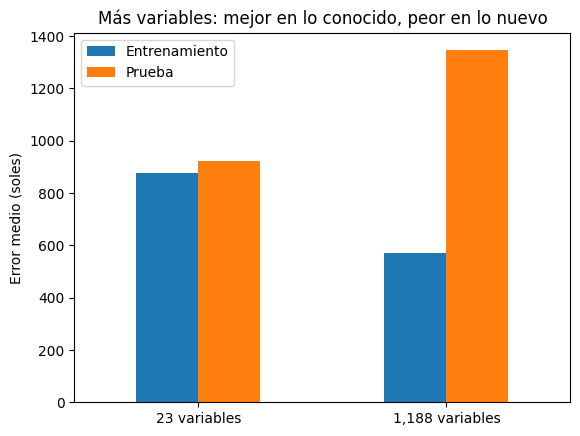

In [8]:
resultados = pd.DataFrame(
    {"Entrenamiento": [878, 570], "Prueba": [921, 1346]},
    index=["23 variables", "1,188 variables"],
)

resultados.plot(
    kind="bar",
    title="Más variables: mejor en lo conocido, peor en lo nuevo",
    ylabel="Error medio (soles)",
    rot=0,
)
plt.show()

> ⚠️ **La señal de alarma:** un error mucho menor en entrenamiento que en prueba. Por eso, en el episodio 1.3 guardamos datos aparte. Si evalúas con lo mismo que entrenaste, nunca lo verás.

¿Cómo se evita?

- **Compara siempre** entrenamiento y prueba.
- **Empieza simple**, y agrega variables solo si mejoran con datos que el modelo no vio.
- **Consigue más datos:** 1,188 variables para 3,475 filas son demasiadas.

Pero ojo: tampoco puedes probar 50 variantes y quedarte con la que mejor salga en la prueba, porque también estarías haciendo trampa. Para elegir entre variantes, se reserva otra parte de los datos.

## 🤖 Pídeselo a la IA

> *"Mi modelo tiene un error de S/ 100 en entrenamiento y de S/ 900 en prueba. Explícame qué está pasando con una analogía de oficina, y qué debería intentar."*

La IA te ayuda a escribir y entender código, pero **tú debes entender lo que hace**. Revisa cada respuesta antes de usarla, y no pegues datos de tu empresa.

## ✅ Resumen

| En Excel | En Python |
|---|---|
| Una fórmula con un `=SI()` (`IF`) para cada caso | Un modelo con demasiadas variables |
| Probar la fórmula en el mismo archivo | Error en entrenamiento |
| Probar la fórmula en un mes nuevo | Error en prueba |
| | **Sobreajuste:** error de prueba mucho mayor que el de entrenamiento |

## 📝 Ahora te toca

Abre [el ejercicio en Colab](https://colab.research.google.com/github/PercyTechX/del-excel-al-ml/blob/main/temporada-1/06-sobreajuste/ejercicio.ipynb) y lleva el sobreajuste al extremo. Cuando termines, compara con [la solución](https://colab.research.google.com/github/PercyTechX/del-excel-al-ml/blob/main/temporada-1/06-sobreajuste/solucion.ipynb).

---

*Del Excel al Machine Learning* · por [Percy Nazario](https://www.linkedin.com/in/percy-nazario/) · [Repositorio](https://github.com/PercyTechX/del-excel-al-ml) · Contenido bajo licencia CC BY 4.0